<a href="https://colab.research.google.com/github/davichomendez1901-byte/Simulaci-n-Remix/blob/main/Ejemploderiva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:crimson"> Ejemlo de puente Brawniano. </span>

En este notebook se buscara encontrar la probabilidad de que el movimiento browniano con parámetro deriva, $\mu=0.6$, y varianza, $\sigma^2=0.25$, tome valores entre $1$ y $3$ al tiempo $4$.

## Solución analítica

Consideramos un movimiento browniano con deriva:

$$
X_t = \mu t + \sigma B_t
$$

donde:

$$
\mu = 0.6, \qquad \sigma^2 = 0.25
$$

por lo tanto,

$$
\sigma = \sqrt{0.25}=0.5.
$$

Queremos calcular:

$$
P(1<X_4<3).
$$

Para $t=4$:

$$
X_4 = 0.6(4)+0.5B_4
$$

$$
X_4 = 2.4+0.5B_4.
$$

Entonces:

$$
P(1<X_4<3)
=
P(1<2.4+0.5B_4<3).
$$

Restando $2.4$:

$$
P(-1.4<0.5B_4<0.6).
$$

Dividiendo entre $0.5$:

$$
P(-2.8<B_4<1.2).
$$

Sabemos que para un movimiento browniano estándar:

$$
B_t \sim N(0,t).
$$

Por tanto:

$$
B_4 \sim N(0,4).
$$

Como la desviación estándar de $B_4$ es:

$$
\sqrt{4}=2,
$$

estandarizamos:

$$
Z=\frac{B_4}{2}.
$$

Así:

$$
P(-2.8<B_4<1.2)
=
P\left(\frac{-2.8}{2}<Z<\frac{1.2}{2}\right)
$$

$$
=
P(-1.4<Z<0.6).
$$

Utilizando la función de distribución acumulada de la normal estándar:

$$
P(-1.4<Z<0.6)
=
\Phi(0.6)-\Phi(-1.4).
$$

Por lo tanto:

$$
P(1<X_4<3)
\approx 0.6449.
$$

Finalmente,

$$
\boxed{P(1<X_4<3)\approx 0.645}
$$

es decir, existe aproximadamente un **64.5 % de probabilidad** de que el proceso se encuentre entre 1 y 3 en el tiempo $t=4$.

##Solution By Simulation :)
Los primmero que hacemos es programar el metodo de Deriva.
Definido por
$$
X_t = \mu t + \sigma B_t
$$

Donde $\mu$ representa la deriva del proceso, $\sigma$ controla la volatilidad y $B_t$ corresponde a un movimiento Brawniano estandar.

Para simularlo númericamente dividimos el intervalo $[0,t]$ en $n$ sub intervalos de tamaño $\Delta = t \frac {T}{n}$
Los incrementos del movimiento browniano cumplen

$$
\Delta B_t \sim N(0,\Delta t),
$$

por lo que pueden simularse mediante

$$
\Delta B_t=\sqrt{\Delta t}\,Z,
\qquad Z\sim N(0,1).
$$

Por lo tanto, la actualización del proceso en cada paso está dada por

$$
X_{i+1}
=
X_i+\mu\Delta t+\sigma\sqrt{\Delta t}\,Z.
$$

Esta expresión es la que se implementa en la función de Python para generar
una trayectoria del movimiento browniano con deriva.

In [26]:
import numpy as np

def browniano_deriva(mu, sigma, T, n):

    dt = T / n
    t = np.linspace(0, T, n + 1)

    X = np.zeros(n + 1)

    for i in range(n):

        Z = np.random.normal(0, 1)

        X[i + 1] = (
            X[i]
            + mu * dt
            + sigma * np.sqrt(dt) * Z
        )

    return t, X

In [27]:
t, X = browniano_deriva(
    mu=0.6,
    sigma=0.5,
    T=4,
    n=1000
)

print(X[-1])

4.533780099338565


In [24]:
N= 10000
contador = 0

for j in range(N):

    t, X = browniano_deriva(
        mu=0.6,
        sigma=0.5,
        T=4,
        n=1000
    )

    if 1 < X[-1] < 3:
        contador += 1

probabilidad = contador / N

print("Veces que X4 estuvo entre 1 y 3:", contador)
print("Probabilidad estimada:", probabilidad)

Veces que X4 estuvo entre 1 y 3: 6465
Probabilidad estimada: 0.6465


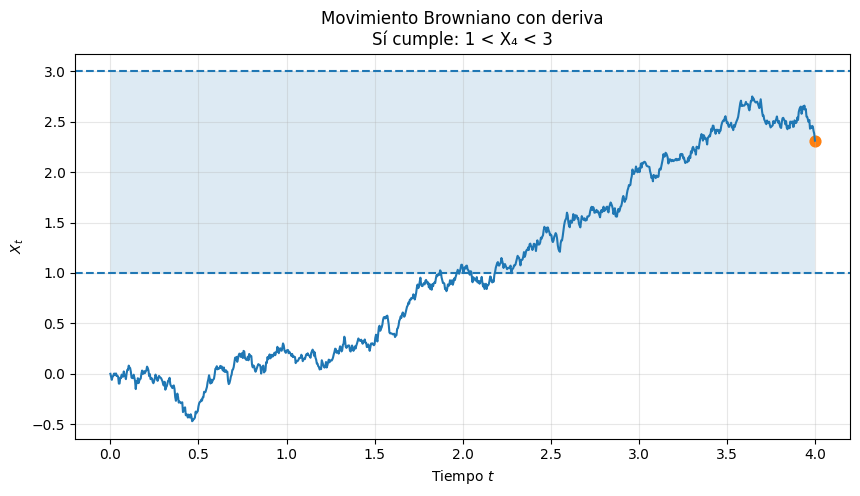

In [25]:
import matplotlib.pyplot as plt
if 1 < X[-1] < 3:
    resultado = "Sí cumple: 1 < X₄ < 3"
else:
    resultado = "No cumple: 1 < X₄ < 3"

plt.figure(figsize=(10,5))

plt.plot(t, X)
plt.axhline(1, linestyle="--")
plt.axhline(3, linestyle="--")
plt.fill_between(t, 1, 3, alpha=0.15)

plt.scatter(t[-1], X[-1], s=60)

plt.xlabel("Tiempo $t$")
plt.ylabel("$X_t$")
plt.title(f"Movimiento Browniano con deriva\n{resultado}")

plt.grid(alpha=0.3)
plt.show()

Conclusiones

A partir de la simulación del movimiento browniano con deriva se pudo representar numéricamente el proceso
$$
[
X_t=\mu t+\sigma B_t,
]
$$
considerando una deriva $\mu=0.6$ y una volatilidad $\sigma=0.5$.

Mediante el método de Monte Carlo se estimó la probabilidad de que el proceso se encuentre entre 1 y 3 en el instante $t=4$, es decir,
$$
[
P(1<X_4<3).
]
$$

Al realizar un número grande de simulaciones, la frecuencia relativa obtenida se aproxima al valor analítico de

$$
[
P(1<X_4<3)\approx 0.645,
]
$$

lo que corresponde aproximadamente a una probabilidad del $64.5%$.

La comparación entre la solución analítica y la simulación permite comprobar que el método Monte Carlo proporciona una buena aproximación de la probabilidad teórica. Además, mientras mayor sea el número de simulaciones, menor será la variabilidad del resultado estimado y, en general, más cercana será la aproximación al valor teórico.

Finalmente, la representación gráfica permite observar una trayectoria posible del proceso, así como identificar visualmente si el valor final $X_4$ se encuentra dentro del intervalo $(1,3)$. De esta manera, la simulación complementa la solución analítica y facilita la interpretación del comportamiento del movimiento browniano con deriva.